In [1]:
import numpy as np
import pandas as pd
import statsmodels.api as sm
from cmdstanpy import CmdStanModel
from scipy import stats
import matplotlib.pyplot as plt
plt.style.use('tableau-colorblind10')

## Bayesian AR (copy from previous notebook)

In [2]:
# Load data
unrate = pd.read_csv('data/UNRATE.csv', index_col='observation_date', parse_dates=True)
unrate = unrate.loc[:'2019']
y_full = unrate['UNRATE'].values

In [3]:
p = 12 # lag length
X = sm.tsa.tsatools.lagmat(y_full, maxlag=p, trim='both') # lag matrix

# Data for Stan
std_y = y_full.std()
stan_data = {
    'T': X.shape[0],
    'p': p,
    'y': y_full[p:],
    'X': X,
    'lambda': 0.2,
    'scale_sigma': std_y,
    'scale_c': 100*std_y,
}

# Compile and sample
model = CmdStanModel(stan_file='slides12_ar.stan')
fit = model.sample(data=stan_data, seed=31150, chains=4,
                   iter_warmup=1000, iter_sampling=1000, show_progress=True)

print(fit.summary())

11:40:04 - cmdstanpy - INFO - CmdStan start processing


chain 1:   0%|          | 0/2000 [00:00<?, ?it/s, (Warmup)]

chain 2:   0%|          | 0/2000 [00:00<?, ?it/s, (Warmup)]

chain 3:   0%|          | 0/2000 [00:00<?, ?it/s, (Warmup)]

chain 4:   0%|          | 0/2000 [00:00<?, ?it/s, (Warmup)]

11:40:10 - cmdstanpy - INFO - CmdStan done processing.
11:40:10 - cmdstanpy - WARNING - Non-fatal error during sampling:
Exception: normal_lpdf: Scale parameter is 0, but must be positive! (in 'slides12_ar.stan', line 32, column 2 to column 31)
Consider re-running with show_console=True if the above output is unclear!



              Mean      MCSE    StdDev       MAD           5%          50%  \
lp__   1010.280000  0.063370  2.759430  2.557710  1005.270000  1010.630000   
c         0.089636  0.000391  0.025454  0.025671     0.047837     0.089861   
a[1]      1.012370  0.000595  0.032229  0.032269     0.960301     1.011730   
a[2]      0.172059  0.000791  0.042703  0.042244     0.099819     0.172488   
a[3]     -0.045320  0.000651  0.037394  0.037117    -0.106699    -0.044841   
a[4]     -0.046709  0.000604  0.033100  0.033077    -0.101172    -0.047124   
a[5]     -0.022017  0.000501  0.029876  0.030123    -0.070184    -0.022069   
a[6]     -0.055230  0.000435  0.026066  0.026362    -0.097376    -0.055347   
a[7]     -0.029408  0.000372  0.023062  0.023177    -0.066451    -0.029906   
a[8]     -0.006612  0.000336  0.020786  0.020602    -0.040138    -0.006695   
a[9]     -0.006951  0.000293  0.019024  0.019120    -0.038650    -0.006727   
a[10]    -0.006285  0.000267  0.016710  0.016886    -0.033778  

## Forecast

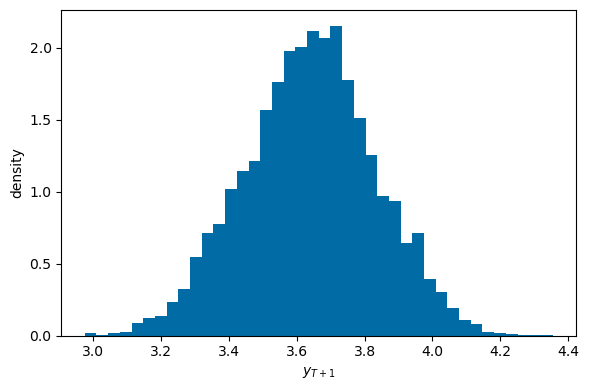

In [4]:
# Extract parameter draws
draws = fit.draws_pd()
c_draws = draws['c'].values
a_draws = draws[[f'a[{l}]' for l in range(1, p+1)]].values
sigma_draws = draws['sigma'].values

# Simulate y_{T+1}
rng = np.random.default_rng(seed=31150)
x_new = y_full[-p:][::-1]  # p most recent observations in reverse order
mean_draws = c_draws + a_draws @ x_new # y_{T+1|T}
y_Tp1 = rng.normal(mean_draws, sigma_draws)

fig, ax = plt.subplots(figsize=(6, 4))
ax.hist(y_Tp1, bins=40, density=True)
ax.set_xlabel(r'$y_{T+1}$')
ax.set_ylabel('density')
plt.tight_layout()
fig.savefig('output/bayes_ar_forecast.eps')
plt.show()

## ARCH innovations
$u_t \sim N(0,\sigma_t^2),\quad \sigma_t^2 = \omega + \gamma u_{t-1}^2$

In [5]:
# Data for Stan
stan_data_arch = {
    'T': X.shape[0],
    'p': p,
    'y': y_full[p:],
    'X': X,
    'lambda': 0.2,
    'scale_c': 100*std_y,
    'scale_omega': (5*std_y)**2, # parameter omega is on a variance scale, not std
}

# Compile and sample
model_arch = CmdStanModel(stan_file='slides13_arch.stan')
fit_arch = model_arch.sample(data=stan_data_arch, seed=31150, chains=4,
                             iter_warmup=1000, iter_sampling=1000, show_progress=True)

summary_arch = fit_arch.summary()
print(summary_arch[~summary_arch.index.str.startswith('sigma2[')]) # don't print sigma2 parameter vector

11:40:11 - cmdstanpy - INFO - CmdStan start processing


chain 1:   0%|          | 0/2000 [00:00<?, ?it/s, (Warmup)]

chain 2:   0%|          | 0/2000 [00:00<?, ?it/s, (Warmup)]

chain 3:   0%|          | 0/2000 [00:00<?, ?it/s, (Warmup)]

chain 4:   0%|          | 0/2000 [00:00<?, ?it/s, (Warmup)]

11:40:44 - cmdstanpy - INFO - CmdStan done processing.



              Mean      MCSE    StdDev       MAD           5%          50%  \
lp__   1056.690000  0.073268  2.730380  2.647550  1051.720000  1057.020000   
c         0.084593  0.000350  0.024083  0.024127     0.044606     0.084890   
a[1]      0.995546  0.000647  0.039940  0.040167     0.931415     0.994874   
a[2]      0.160400  0.000708  0.044672  0.044516     0.085161     0.160818   
a[3]     -0.019503  0.000506  0.035901  0.036535    -0.078763    -0.019148   
a[4]     -0.018829  0.000438  0.031234  0.031601    -0.070620    -0.018047   
a[5]     -0.028655  0.000415  0.028898  0.028814    -0.076871    -0.028514   
a[6]     -0.048257  0.000349  0.024610  0.025091    -0.089085    -0.048518   
a[7]     -0.037151  0.000347  0.022770  0.022625    -0.074898    -0.037294   
a[8]     -0.015591  0.000299  0.020566  0.020098    -0.049347    -0.015622   
a[9]     -0.013531  0.000254  0.018155  0.018216    -0.042645    -0.013386   
a[10]    -0.010273  0.000242  0.016650  0.016599    -0.037973  

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


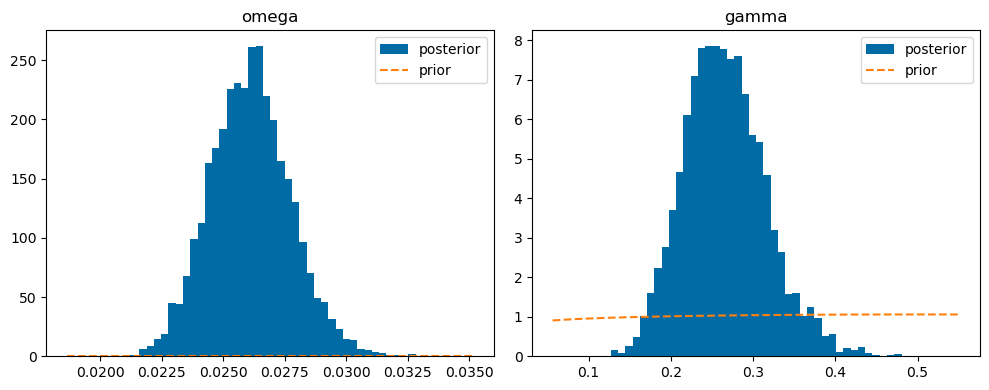

In [6]:
# Posterior vs. prior
prior_pdf_arch = {
    'omega': lambda x: 2 * stats.norm.pdf(x, 0, stan_data_arch['scale_omega']) * (x >= 0),
    'gamma': lambda x: stats.beta.pdf(x, 1.1, 1.1),
}

params_arch = ['omega', 'gamma']

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, name in zip(axes, params_arch):
    draws_p = fit_arch.stan_variable(name)
    lo, hi = draws_p.min(), draws_p.max()
    pad = 0.2 * (hi - lo)
    grid = np.linspace(lo - pad, hi + pad, 400)
    ax.hist(draws_p, bins=40, density=True, label='posterior')
    ax.plot(grid, prior_pdf_arch[name](grid), '--', label='prior')
    ax.set_title(name)
    ax.legend()
plt.tight_layout()
fig.savefig('output/bayes_arch_posterior.eps')
plt.show()

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


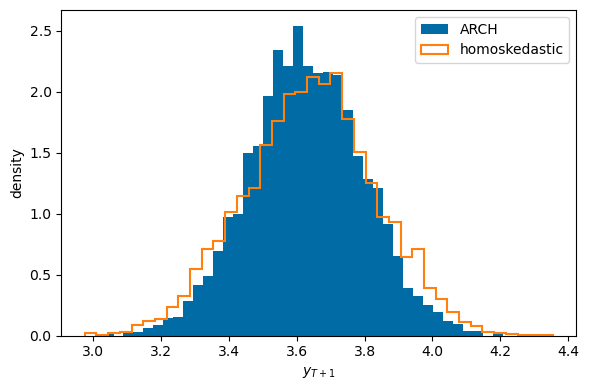

In [7]:
# Posterior predictive draws of y_{T+1}
draws_arch = fit_arch.draws_pd()
c_draws_arch = draws_arch['c'].values
a_draws_arch = draws_arch[[f'a[{l}]' for l in range(1, p+1)]].values
omega_draws = draws_arch['omega'].values
gamma_draws = draws_arch['gamma'].values

# Most recent residual u_T
u_T = y_full[-1] - (c_draws_arch + a_draws_arch @ X[-1, :])

# Conditional variance of y_{T+1}
sigma2_Tp1 = omega_draws + gamma_draws * u_T**2

# Simulate y_{T+1}
mean_draws_arch = c_draws_arch + a_draws_arch @ x_new # y_{T+1|T}
y_Tp1_arch = rng.normal(mean_draws_arch, np.sqrt(sigma2_Tp1))

fig, ax = plt.subplots(figsize=(6, 4))
ax.hist(y_Tp1_arch, bins=40, density=True, label='ARCH')
ax.hist(y_Tp1, bins=40, density=True, histtype='step', lw=1.5, label='homoskedastic')
ax.set_xlabel(r'$y_{T+1}$')
ax.set_ylabel('density')
ax.legend()
plt.tight_layout()
fig.savefig('output/bayes_arch_forecast.eps')
plt.show()

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


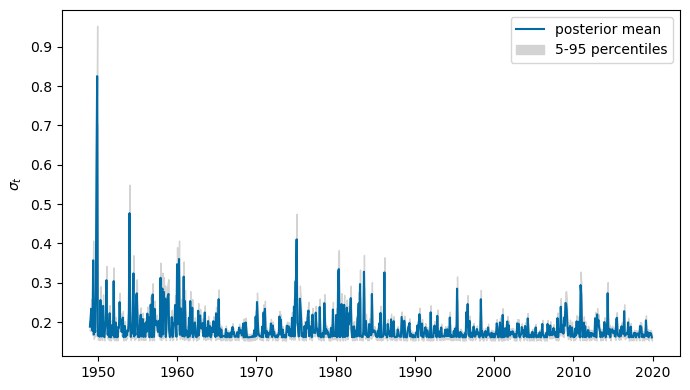

In [8]:
# Conditional volatility: posterior mean and 5-95 percentile band
sigma2_draws_arch = fit_arch.stan_variable('sigma2') # (B, T)
vol_draws_arch = np.sqrt(sigma2_draws_arch)
vol_mean_arch = vol_draws_arch.mean(axis=0)
vol_lo_arch, vol_hi_arch = np.percentile(vol_draws_arch, [5, 95], axis=0)

dates = unrate.index[p:]
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(dates, vol_mean_arch, label='posterior mean')
ax.fill_between(dates, vol_lo_arch, vol_hi_arch, color='lightgrey', label='5-95 percentiles')
ax.set_ylabel(r'$\sigma_t$')
ax.legend()
plt.tight_layout()
fig.savefig('output/bayes_arch_volatility.eps')
plt.show()

## Bayesian VAR

$E[A_{\ell,ij}] = \begin{cases} 1 & \text{if } i=j \text{ and } \ell=1 \\ 0 & \text{otherwise} \end{cases}$

$\text{Var}(A_{\ell,ij}) = \begin{cases} \left(\frac{\lambda}{\ell}\right)^2 & \text{if } i=j \\ \left(\frac{\lambda \kappa}{\ell} \times \frac{\hat{\sigma}_i}{\hat{\sigma}_j}\right)^2 & \text{otherwise} \end{cases}$

In [9]:
# Load data

# Monthly series
svar = pd.read_csv('data/svar_data.csv', index_col='observation_date', parse_dates=True)
svar = svar.rename(columns={'WPSID62': 'PCOM'})

# Weekly series
nfci_weekly = pd.read_csv('data/NFCI.csv', index_col='observation_date', parse_dates=True)
nfci_monthly = nfci_weekly.resample('MS').mean()

# Merge
df = svar.join(nfci_monthly, how='inner')
df = df.loc[:'2019'] # drop post-2020 data

# Transform to logs
for var in ['CPIAUCSL', 'INDPRO', 'PCOM']:
    df[f'l_{var}'] = 100 * np.log(df[[var]])

# SVAR ordering
order = ['l_INDPRO', 'UNRATE', 'l_CPIAUCSL', 'l_PCOM', 'FEDFUNDS', 'NFCI']
Y_svar = df[order].values

# Standardize data series (improves posterior sampling)
Y_mean = Y_svar.mean(axis=0)
Y_std = Y_svar.std(axis=0)
Y_svar = (Y_svar - Y_mean) / Y_std

In [10]:
p = 4 # lag length
X = sm.tsa.tsatools.lagmat(Y_svar, maxlag=p, trim='both') # lag matrix

# Residual std. dev. from VAR(p) fit by OLS (used as Minnesota prior scale)
var_ols = sm.tsa.VAR(pd.DataFrame(Y_svar, columns=order)).fit(maxlags=p)
sigma_hat = np.sqrt(np.diag(var_ols.sigma_u))

In [11]:
# Data for Stan
n = Y_svar.shape[1]
stan_data_bvar = {
    'T': X.shape[0],
    'n': n,
    'p': p,
    'Y': Y_svar[p:],
    'X': X,
    'lambda': 0.2,
    'kappa': 0.3,
    'scale_sigma': sigma_hat,
    'scale_c': 100*np.ones(n), # data already standardized
}

# Compile and sample (WARNING: this may take several minutes)
model_bvar = CmdStanModel(stan_file='slides13_bvar.stan')
fit_bvar = model_bvar.sample(data=stan_data_bvar, seed=31150, chains=4, metric='dense_e',
                             iter_warmup=1000, iter_sampling=1000, show_progress=True)
# metric='dense_e' improves sampling in this model

print(fit_bvar.summary())

11:40:49 - cmdstanpy - INFO - CmdStan start processing


chain 1:   0%|          | 0/2000 [00:00<?, ?it/s, (Warmup)]

chain 2:   0%|          | 0/2000 [00:00<?, ?it/s, (Warmup)]

chain 3:   0%|          | 0/2000 [00:00<?, ?it/s, (Warmup)]

chain 4:   0%|          | 0/2000 [00:00<?, ?it/s, (Warmup)]

11:59:24 - cmdstanpy - INFO - CmdStan done processing.
11:59:24 - cmdstanpy - WARNING - Non-fatal error during sampling:
Exception: inv_wishart_lpdf: random variable is not symmetric. random variable[1,2] = nan, but random variable[2,1] = nan (in 'slides13_bvar.stan', line 47, column 2 to column 42)
	Exception: inv_wishart_lpdf: random variable is not symmetric. random variable[1,2] = nan, but random variable[2,1] = nan (in 'slides13_bvar.stan', line 47, column 2 to column 42)
	Exception: inv_wishart_lpdf: random variable is not symmetric. random variable[1,2] = nan, but random variable[2,1] = nan (in 'slides13_bvar.stan', line 47, column 2 to column 42)
	Exception: inv_wishart_lpdf: random variable is not symmetric. random variable[1,2] = -inf, but random variable[2,1] = -inf (in 'slides13_bvar.stan', line 47, column 2 to column 42)
	Exception: inv_wishart_lpdf: random variable is not symmetric. random variable[1,2] = -inf, but random variable[2,1] = -inf (in 'slides13_bvar.stan', lin


                   Mean          MCSE    StdDev       MAD           5%  \
lp__        9254.240000  2.395990e-01  9.429520  9.567880  9238.330000   
c[1]           0.004034  2.064740e-05  0.001295  0.001301     0.001904   
c[2]          -0.000785  9.230410e-05  0.006426  0.006411    -0.011488   
c[3]           0.003915  5.857360e-06  0.000358  0.000367     0.003319   
c[4]           0.000751  7.400640e-05  0.004849  0.004762    -0.007438   
...                 ...           ...       ...       ...          ...   
Sigma[6,2]    -0.001048  7.920770e-06  0.000570  0.000569    -0.001979   
Sigma[6,3]     0.000027  3.921240e-07  0.000026  0.000025    -0.000017   
Sigma[6,4]    -0.000704  5.782270e-06  0.000409  0.000406    -0.001369   
Sigma[6,5]     0.006949  1.164310e-05  0.000782  0.000795     0.005725   
Sigma[6,6]     0.019827  2.204190e-05  0.001280  0.001251     0.017803   

                    50%          95%  ESS_bulk  ESS_tail  ESS_bulk/s     R_hat  
lp__        9254.610000  9268

In [12]:
print(fit_bvar.diagnose())

Checking sampler transitions treedepth.
Treedepth satisfactory for all transitions.

Checking sampler transitions for divergences.
No divergent transitions found.

Checking E-BFMI - sampler transitions HMC potential energy.
E-BFMI satisfactory.

Rank-normalized split effective sample size satisfactory for all parameters.

Rank-normalized split R-hat values satisfactory for all parameters.

Processing complete, no problems detected.



## IRF

In [13]:
# Extract parameter draws
A_draws = fit_bvar.stan_variable('A')          # (B, n, n*p), [A_1, ..., A_p]
Sigma_draws = fit_bvar.stan_variable('Sigma')  # (B, n, n)
B = A_draws.shape[0]                           # number of posterior draws

# Compute IRF draws
max_horizon = 48
response_index = order.index('l_INDPRO')
shock_index = order.index('FEDFUNDS')

irf_draws = np.empty((B, max_horizon + 1))
for b in range(B):
    # Companion matrix
    A_comp = np.zeros((n*p, n*p))
    A_comp[:n, :] = A_draws[b]
    A_comp[n:, :-n] = np.eye(n*(p-1))

    # Cholesky factor of innovation var-cov matrix
    H = np.linalg.cholesky(Sigma_draws[b])

    # Compute IRF iteratively using formula A_comp^h * H
    irf_draws[b, 0] = H[response_index, shock_index] # impact response
    Ah_H = np.concatenate([H[:, shock_index],
                           np.zeros(n*(p-1))])
    for h in range(1, max_horizon + 1):
        Ah_H = A_comp @ Ah_H # IRFs of all variables wrt. shock
        irf_draws[b, h] = Ah_H[response_index]

irf_draws *= Y_std[response_index] # undo earlier variable standardization

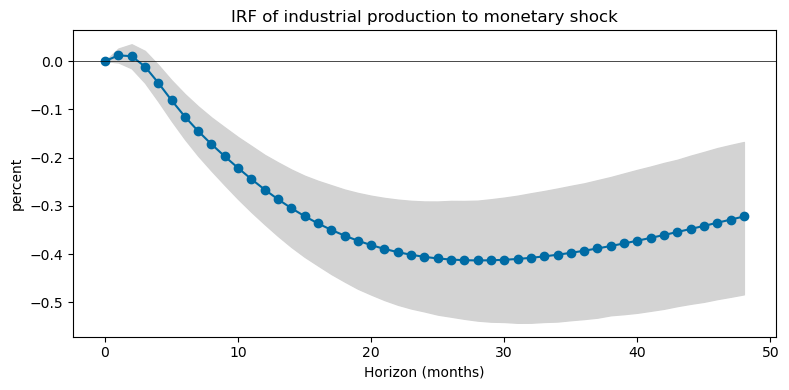

In [14]:
# Posterior mean and 68% credible band
irf_mean = irf_draws.mean(axis=0)
irf_lo, irf_hi = np.percentile(irf_draws, [16, 84], axis=0)

# Plot
h_grid = np.arange(max_horizon + 1)
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(h_grid, irf_mean, marker='o')
ax.fill_between(h_grid, irf_lo, irf_hi, color='lightgrey')
ax.axhline(0, color='k', linewidth=0.5)
ax.set_xlabel('Horizon (months)')
ax.set_ylabel('percent')
ax.set_title('IRF of industrial production to monetary shock')
plt.tight_layout()
fig.savefig('output/bayes_svar_irf.eps')
plt.show()